<a href="https://colab.research.google.com/github/JorPinales/Desarrollo-de-Aplicaciones-Con-Inteligencia-Artificial/blob/main/HortiAmiga_multimodal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HortiAmiga multimodal — Avance de proyecto 2

Clasificación de intenciones con NLP y análisis visual de hojas de jitomate mediante **ResNet50 con transferencia de aprendizaje**.

Este notebook conserva el problema, los usuarios y el alcance del Avance 1, pero sustituye la detección manual de intenciones por un clasificador supervisado e incorpora un componente de visión por computadora.

> El resultado visual es orientativo y no sustituye el diagnóstico de una persona especialista en agronomía o fitosanidad.

## 1. Preparación del entorno

El notebook está diseñado para Google Colab. Para el entrenamiento visual se recomienda seleccionar **Entorno de ejecución -> Cambiar tipo de entorno de ejecución -> GPU**.

In [1]:
!pip -q install tensorflow-datasets nltk seaborn scikit-learn joblib

import os
import re
import random
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Entorno preparado.")

Entorno preparado.


## 2. Conjunto de datos textual

El conjunto contiene **250 mensajes**, distribuidos equitativamente entre diez clases: nueve intenciones del prototipo y `fallback`. Cada clase tiene 25 expresiones distintas.

In [2]:
# En Colab, el CSV puede cargarse desde el repositorio o subirse manualmente.
RUTA_CSV = "datos/intenciones_hortiamiga.csv"

if not Path(RUTA_CSV).exists():
    from google.colab import files
    print("Selecciona el archivo intenciones_hortiamiga.csv")
    subidos = files.upload()
    RUTA_CSV = next(iter(subidos))

df = pd.read_csv(RUTA_CSV)
print(df.shape)
display(df.head())
display(df["intencion"].value_counts().sort_index())

assert df.shape[0] == 250
assert df["intencion"].value_counts().nunique() == 1
assert not df.duplicated(subset=["texto"]).any()

Selecciona el archivo intenciones_hortiamiga.csv


Saving intenciones_hortiamiga.csv to intenciones_hortiamiga.csv
(250, 2)


,texto,intencion
0,hola,saludo
1,hola hortiamiga,saludo
2,buenos dias,saludo
3,buenas tardes,saludo
4,buenas noches,saludo


,count
intencion,
consultar_iluminacion,25
consultar_problema,25
consultar_riego,25
consultar_sustrato,25
consultar_temporada,25
despedida,25
fallback,25
iniciar_huerto,25
recomendar_hortaliza,25


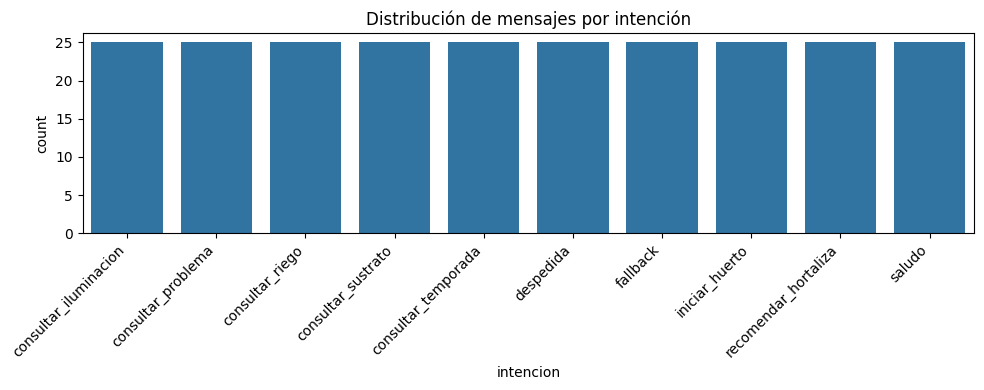

In [3]:
plt.figure(figsize=(10, 4))
sns.countplot(data=df, x="intencion", order=sorted(df["intencion"].unique()))
plt.xticks(rotation=45, ha="right")
plt.title("Distribución de mensajes por intención")
plt.tight_layout()
plt.show()

## 3. Preprocesamiento de texto

El pipeline aplica minúsculas, eliminación de acentos, tokenización, eliminación de stopwords y stemming en español con `SnowballStemmer`. Se conservan algunas negaciones porque pueden modificar el significado de la consulta.

In [4]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import RegexpTokenizer
from nltk.stem import SnowballStemmer

nltk.download("stopwords", quiet=True)

tokenizer = RegexpTokenizer(r"[a-záéíóúñü]+")
stemmer = SnowballStemmer("spanish")
STOPWORDS = set(stopwords.words("spanish")) - {"no", "ni", "sin"}

def normalizar_texto(texto):
    texto = str(texto).lower().strip()
    texto = unicodedata.normalize("NFKD", texto)
    texto = "".join(c for c in texto if not unicodedata.combining(c))
    return re.sub(r"\s+", " ", texto)

def preprocesar_texto(texto):
    tokens = tokenizer.tokenize(normalizar_texto(texto))
    tokens = [t for t in tokens if t not in STOPWORDS]
    return " ".join(stemmer.stem(t) for t in tokens)

df["texto_procesado"] = df["texto"].apply(preprocesar_texto)
display(df.sample(10, random_state=SEED))

,texto,intencion,texto_procesado
142,puedo cultivar con luz indirecta,consultar_iluminacion,pued cultiv luz indirect
6,como estas,saludo,
97,puedo sembrar cebolla ahora,consultar_temporada,pued sembr ceboll ahor
60,quiero una planta comestible facil,recomendar_hortaliza,quier plant comest facil
112,el rabano necesita mucha agua,consultar_riego,raban necesit much agu
181,mi albahaca tiene cochinilla,consultar_problema,albahac cochinill
197,veo una capa blanca sobre la planta,consultar_problema,veo cap blanc plant
184,que hago con las manchas cafes,consultar_problema,hag manch caf
9,buen dia,saludo,buen dia
104,como regar mi albahaca,consultar_riego,reg albahac


## 4. Representación y clasificación de intenciones

Se comparan dos estrategias vistas en clase:

1. Bag of Words con Naive Bayes multinomial.
2. TF-IDF con unigramas y bigramas más SVM lineal.

La partición es estratificada para conservar la misma proporción de clases en entrenamiento y prueba.

In [5]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)

X_train, X_test, y_train, y_test = train_test_split(
    df["texto"], df["intencion"],
    test_size=0.20, random_state=SEED,
    stratify=df["intencion"]
)

modelos_texto = {
    "BoW + Naive Bayes": Pipeline([
        ("bow", CountVectorizer(
            preprocessor=preprocesar_texto,
            tokenizer=str.split,
            token_pattern=None,
            ngram_range=(1, 2)
        )),
        ("modelo", MultinomialNB(alpha=0.5))
    ]),
    "TF-IDF + SVM lineal": Pipeline([
        ("tfidf", TfidfVectorizer(
            preprocessor=preprocesar_texto,
            tokenizer=str.split,
            token_pattern=None,
            ngram_range=(1, 2),
            sublinear_tf=True
        )),
        ("modelo", LinearSVC(C=1.0, class_weight="balanced"))
    ])
}

resultados_texto = []
predicciones_texto = {}

for nombre, modelo in modelos_texto.items():
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    predicciones_texto[nombre] = pred
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, pred, average="macro", zero_division=0
    )
    resultados_texto.append({
        "modelo": nombre,
        "accuracy": accuracy_score(y_test, pred),
        "precision_macro": precision,
        "recall_macro": recall,
        "f1_macro": f1
    })

df_metricas_texto = pd.DataFrame(resultados_texto).sort_values("f1_macro", ascending=False)
display(df_metricas_texto.style.format({c: "{:.3f}" for c in df_metricas_texto.columns[1:]}))

,modelo,accuracy,precision_macro,recall_macro,f1_macro
1,TF-IDF + SVM lineal,0.640,0.691,0.640,0.648
0,BoW + Naive Bayes,0.620,0.618,0.620,0.598


In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
filas_cv = []
for nombre, modelo in modelos_texto.items():
    puntajes = cross_val_score(modelo, df["texto"], df["intencion"], cv=cv, scoring="f1_macro")
    filas_cv.append({
        "modelo": nombre,
        "f1_macro_promedio": puntajes.mean(),
        "desviacion": puntajes.std()
    })

df_cv = pd.DataFrame(filas_cv).sort_values("f1_macro_promedio", ascending=False)
display(df_cv.style.format({"f1_macro_promedio": "{:.3f}", "desviacion": "{:.3f}"}))

,modelo,f1_macro_promedio,desviacion
1,TF-IDF + SVM lineal,0.686,0.042
0,BoW + Naive Bayes,0.607,0.048


Modelo seleccionado: TF-IDF + SVM lineal
                       precision    recall  f1-score   support

consultar_iluminacion       1.00      1.00      1.00         5
   consultar_problema       1.00      0.60      0.75         5
      consultar_riego       0.80      0.80      0.80         5
   consultar_sustrato       0.67      0.80      0.73         5
  consultar_temporada       0.57      0.80      0.67         5
            despedida       1.00      0.80      0.89         5
             fallback       0.17      0.20      0.18         5
       iniciar_huerto       0.38      0.60      0.46         5
 recomendar_hortaliza       0.33      0.20      0.25         5
               saludo       1.00      0.60      0.75         5

             accuracy                           0.64        50
            macro avg       0.69      0.64      0.65        50
         weighted avg       0.69      0.64      0.65        50



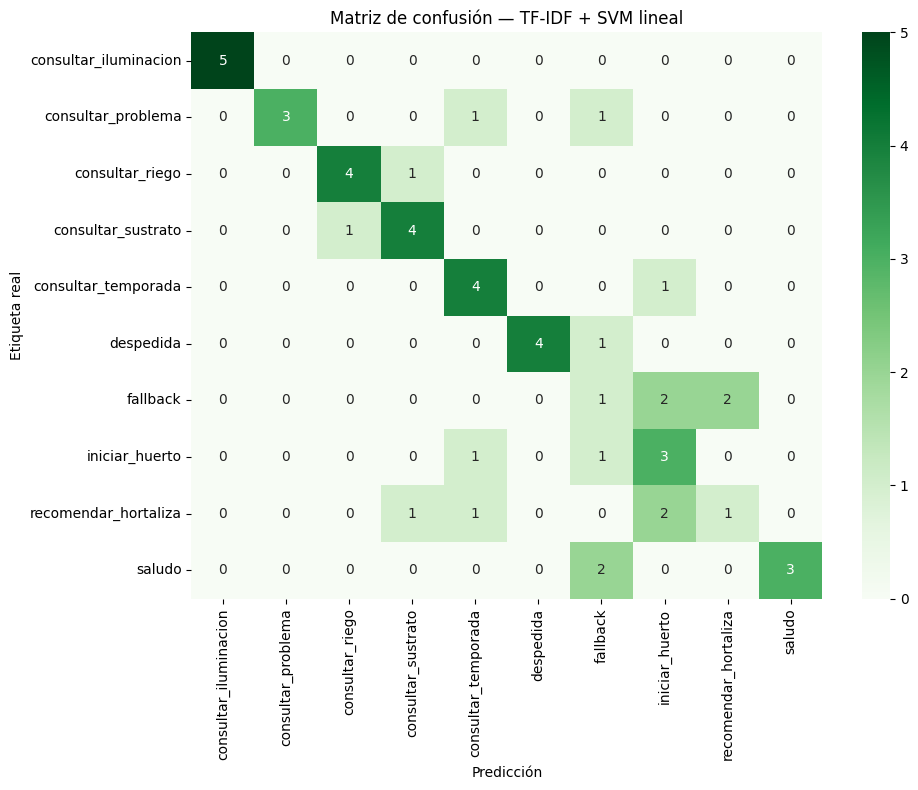

,texto,real,predicha
241,quiero pagar mi colegiatura,fallback,iniciar_huerto
11,que gusto saludarte,saludo,fallback
234,quiero reservar un vuelo,fallback,iniciar_huerto
167,mi maceta retiene demasiada agua,consultar_sustrato,consultar_riego
66,que puedo sembrar en jardineras,recomendar_hortaliza,consultar_temporada
199,el follaje esta cambiando de color,consultar_problema,fallback
36,que debo comprar para iniciar,iniciar_huerto,fallback
231,ayudame con mi tarea de matematicas,fallback,recomendar_hortaliza
69,quiero elegir un cultivo para mi ventana,recomendar_hortaliza,iniciar_huerto
191,el tallo de mi planta esta caido,consultar_problema,consultar_temporada


In [7]:
MEJOR_NOMBRE = df_metricas_texto.iloc[0]["modelo"]
modelo_texto = modelos_texto[MEJOR_NOMBRE]
pred_texto = predicciones_texto[MEJOR_NOMBRE]
etiquetas_texto = sorted(df["intencion"].unique())

print("Modelo seleccionado:", MEJOR_NOMBRE)
print(classification_report(y_test, pred_texto, labels=etiquetas_texto, zero_division=0))

cm_texto = confusion_matrix(y_test, pred_texto, labels=etiquetas_texto)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_texto, annot=True, fmt="d", cmap="Greens",
            xticklabels=etiquetas_texto, yticklabels=etiquetas_texto)
plt.xlabel("Predicción")
plt.ylabel("Etiqueta real")
plt.title(f"Matriz de confusión — {MEJOR_NOMBRE}")
plt.tight_layout()
plt.show()

errores_texto = pd.DataFrame({"texto": X_test, "real": y_test, "predicha": pred_texto})
display(errores_texto[errores_texto["real"] != errores_texto["predicha"]])

In [8]:
# Entrenamiento final con todos los ejemplos y conservación del modelo.
modelo_texto.fit(df["texto"], df["intencion"])
joblib.dump(modelo_texto, "modelo_intenciones_hortiamiga.joblib")
df_metricas_texto.to_csv("metricas_texto.csv", index=False)

mensajes_nuevos = [
    "¿Qué hortaliza puedo sembrar en una maceta?",
    "Mi jitomate tiene manchas oscuras",
    "Necesito recuperar mi contraseña"
]
for mensaje, intencion in zip(mensajes_nuevos, modelo_texto.predict(mensajes_nuevos)):
    print(f"{mensaje} -> {intencion}")

¿Qué hortaliza puedo sembrar en una maceta? -> recomendar_hortaliza
Mi jitomate tiene manchas oscuras -> consultar_problema
Necesito recuperar mi contraseña -> fallback


## 5. Conjunto de imágenes

Se utiliza un subconjunto equilibrado de PlantVillage con cuatro clases de hojas de jitomate:

- Saludable
- Tizón temprano
- Tizón tardío
- Mancha bacteriana

Se toman hasta 800 imágenes por clase para mantener un tiempo de entrenamiento razonable en Colab. El aumento de datos se aplica únicamente al conjunto de entrenamiento.

In [10]:
!pip -q install -U importlib_resources tensorflow-datasets

import shutil
from pathlib import Path

cache_incompleto = Path(
    "/root/tensorflow_datasets/plant_village/1.0.2"
)

if cache_incompleto.exists():
    shutil.rmtree(cache_incompleto)
    print("Se eliminó la descarga incompleta de PlantVillage.")
else:
    print("No se encontró una descarga incompleta.")

print("Dependencias reparadas.")

No se encontró una descarga incompleta.
Dependencias reparadas.


In [11]:
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

raw_ds, info = tfds.load(
    "plant_village",
    split="train",
    as_supervised=True,
    with_info=True,
    shuffle_files=True
)

nombres_originales = info.features["label"].names
for i, nombre in enumerate(nombres_originales):
    if "Tomato" in nombre:
        print(i, nombre)

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/plant_village/incomplete.HBRPOI_1.0.2/plant_village-train.tfrecord-[0-9][0…

Dataset plant_village downloaded and prepared to /root/tensorflow_datasets/plant_village/1.0.2. Subsequent calls will reuse this data.
28 Tomato___Bacterial_spot
29 Tomato___Early_blight
30 Tomato___healthy
31 Tomato___Late_blight
32 Tomato___Leaf_Mold
33 Tomato___Septoria_leaf_spot
34 Tomato___Spider_mites Two-spotted_spider_mite
35 Tomato___Target_Spot
36 Tomato___Tomato_mosaic_virus
37 Tomato___Tomato_Yellow_Leaf_Curl_Virus


In [12]:
CLASES_OBJETIVO = {
    "saludable": "Tomato___healthy",
    "tizon_temprano": "Tomato___Early_blight",
    "tizon_tardio": "Tomato___Late_blight",
    "mancha_bacteriana": "Tomato___Bacterial_spot",
}
MAX_POR_CLASE = 800
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def buscar_id(nombre_esperado):
    normalizado = nombre_esperado.lower().replace("_", "")
    for indice, nombre in enumerate(nombres_originales):
        if nombre.lower().replace("_", "") == normalizado:
            return indice
    raise ValueError(f"No se encontró {nombre_esperado}. Revisa los nombres impresos arriba.")

ids_originales = {amigable: buscar_id(original) for amigable, original in CLASES_OBJETIVO.items()}
class_names = list(CLASES_OBJETIVO.keys())
print(ids_originales)

def extraer_clase(dataset, id_original, nueva_etiqueta):
    return (
        dataset
        .filter(lambda imagen, etiqueta: tf.equal(etiqueta, id_original))
        .map(lambda imagen, etiqueta: (imagen, tf.cast(nueva_etiqueta, tf.int64)),
             num_parallel_calls=AUTOTUNE)
        .take(MAX_POR_CLASE)
    )

partes = []
for nueva_etiqueta, nombre in enumerate(class_names):
    partes.append(extraer_clase(raw_ds, ids_originales[nombre], nueva_etiqueta))

dataset_balanceado = partes[0]
for parte in partes[1:]:
    dataset_balanceado = dataset_balanceado.concatenate(parte)

TOTAL = MAX_POR_CLASE * len(class_names)
dataset_balanceado = dataset_balanceado.shuffle(TOTAL, seed=SEED, reshuffle_each_iteration=False)

n_train = int(TOTAL * 0.70)
n_val = int(TOTAL * 0.15)
n_test = TOTAL - n_train - n_val

train_raw = dataset_balanceado.take(n_train)
val_raw = dataset_balanceado.skip(n_train).take(n_val)
test_raw = dataset_balanceado.skip(n_train + n_val).take(n_test)

def preparar(imagen, etiqueta):
    imagen = tf.image.resize(imagen, IMG_SIZE)
    imagen = tf.cast(imagen, tf.float32)
    return imagen, etiqueta

train_ds = (
    train_raw
    .shuffle(n_train, seed=SEED, reshuffle_each_iteration=True)
    .map(preparar, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)
val_ds = val_raw.map(preparar, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).cache().prefetch(AUTOTUNE)
test_ds = test_raw.map(preparar, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).cache().prefetch(AUTOTUNE)

print({"train": n_train, "validation": n_val, "test": n_test})

{'saludable': 30, 'tizon_temprano': 29, 'tizon_tardio': 31, 'mancha_bacteriana': 28}
{'train': 2240, 'validation': 480, 'test': 480}


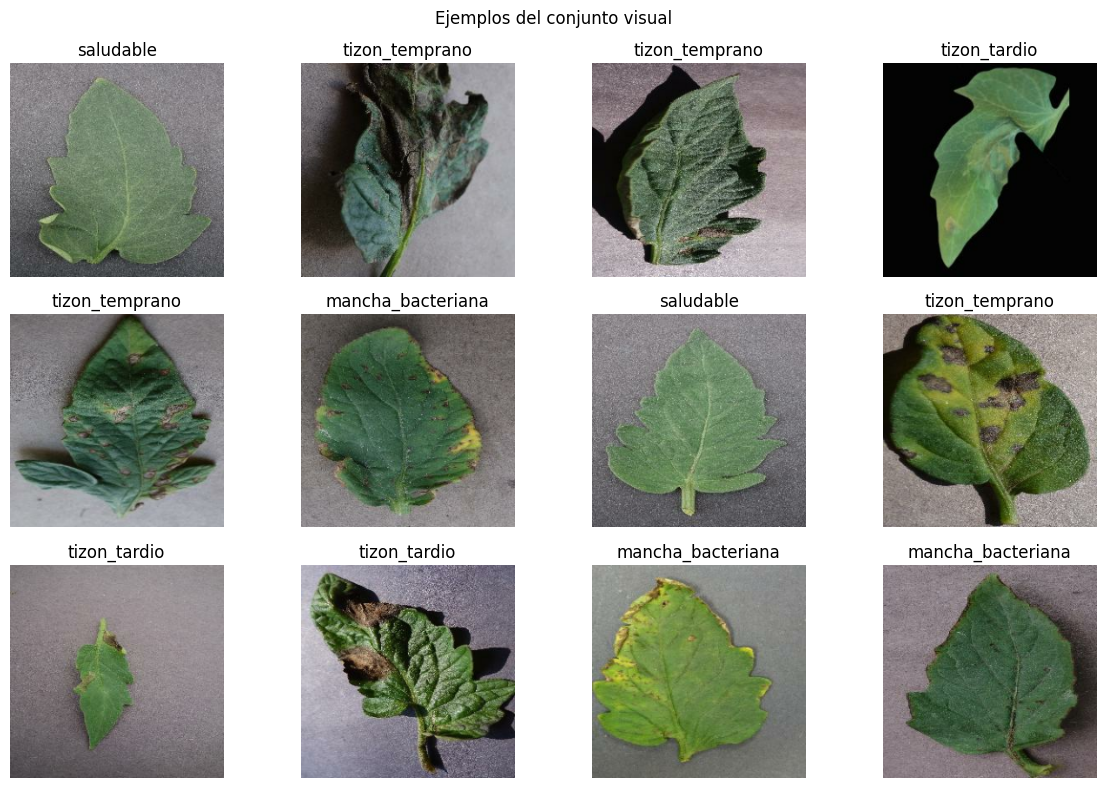

In [13]:
plt.figure(figsize=(12, 8))
for imagenes, etiquetas in train_ds.take(1):
    for i in range(12):
        ax = plt.subplot(3, 4, i + 1)
        plt.imshow(tf.cast(imagenes[i], tf.uint8))
        plt.title(class_names[int(etiquetas[i])])
        plt.axis("off")
plt.suptitle("Ejemplos del conjunto visual")
plt.tight_layout()
plt.show()

## 6. Arquitectura y desarrollo del clasificador visual

ResNet50 se inicializa con pesos de ImageNet y sin su capa clasificadora original. Primero se congela la base convolucional y se entrena una cabeza de clasificación de cuatro salidas.

In [14]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

aumento = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10),
], name="aumento_datos")

base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=IMG_SIZE + (3,)
)
base_model.trainable = False

entradas = keras.Input(shape=IMG_SIZE + (3,), name="imagen")
x = aumento(entradas)
x = preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.30)(x)
salidas = layers.Dense(len(class_names), activation="softmax", name="clase")(x)

modelo_visual = keras.Model(entradas, salidas, name="hortiamiga_resnet50")
modelo_visual.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
modelo_visual.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "hortiamiga_resnet50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ imagen (InputLayer) │ (None, 224, 224,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ aumento_datos       │ (None, 224, 224,  │          0 │ imagen[0][0]      │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ aumento_datos[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ aumento_datos[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ aumento_datos[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 2048)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ clase (Dense)       │ (None, 4)         │      8,196 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 23,595,908 (90.01 MB)

 Trainable params: 8,196 (32.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [15]:
callbacks = [
    keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True, monitor="val_loss"),
    keras.callbacks.ReduceLROnPlateau(patience=2, factor=0.3, min_lr=1e-6),
    keras.callbacks.ModelCheckpoint("hortiamiga_resnet50.keras", save_best_only=True)
]

history = modelo_visual.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    callbacks=callbacks
)

Epoch 1/12
     70/Unknown 72s 136ms/step - accuracy: 0.5111 - loss: 1.2125

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


70/70 ━━━━━━━━━━━━━━━━━━━━ 125s 904ms/step - accuracy: 0.6603 - loss: 0.8477 - val_accuracy: 0.8708 - val_loss: 0.3694 - learning_rate: 0.0010
Epoch 2/12
70/70 ━━━━━━━━━━━━━━━━━━━━ 58s 179ms/step - accuracy: 0.8687 - loss: 0.3659 - val_accuracy: 0.9042 - val_loss: 0.2940 - learning_rate: 0.0010
Epoch 3/12
70/70 ━━━━━━━━━━━━━━━━━━━━ 58s 181ms/step - accuracy: 0.9107 - loss: 0.2716 - val_accuracy: 0.9271 - val_loss: 0.2150 - learning_rate: 0.0010
Epoch 4/12
70/70 ━━━━━━━━━━━━━━━━━━━━ 59s 192ms/step - accuracy: 0.9281 - loss: 0.2242 - val_accuracy: 0.9250 - val_loss: 0.2040 - learning_rate: 0.0010
Epoch 5/12
70/70 ━━━━━━━━━━━━━━━━━━━━ 59s 186ms/step - accuracy: 0.9411 - loss: 0.1928 - val_accuracy: 0.9354 - val_loss: 0.1722 - learning_rate: 0.0010
Epoch 6/12
70/70 ━━━━━━━━━━━━━━━━━━━━ 83s 192ms/step - accuracy: 0.9442 - loss: 0.1632 - val_accuracy: 0.9375 - val_loss: 0.1634 - learning_rate: 0.0010
Epoch 7/12
70/70 ━━━━━━━━━━━━━━━━━━━━ 57s 172ms/step - accuracy: 0.9451 - loss: 0.1630 - val

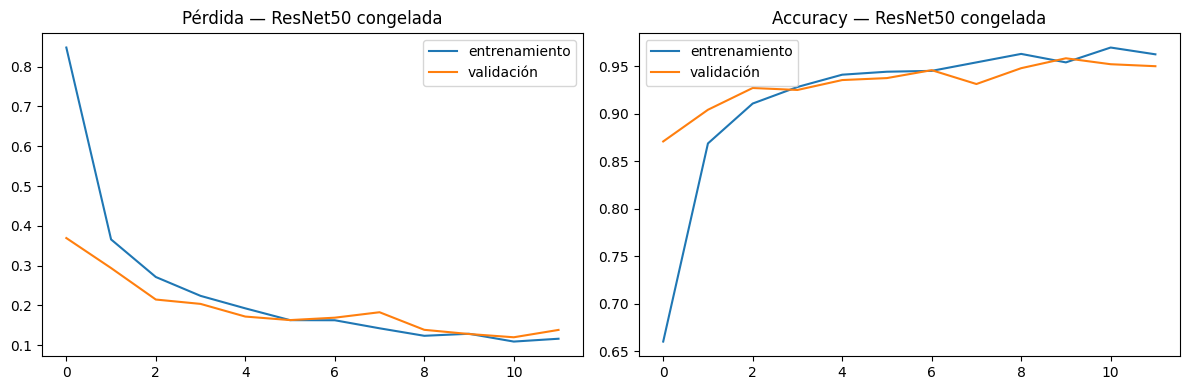

In [16]:
def graficar_historia(historia, titulo):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(historia.history["loss"], label="entrenamiento")
    axes[0].plot(historia.history["val_loss"], label="validación")
    axes[0].set_title(f"Pérdida — {titulo}")
    axes[0].legend()
    axes[1].plot(historia.history["accuracy"], label="entrenamiento")
    axes[1].plot(historia.history["val_accuracy"], label="validación")
    axes[1].set_title(f"Accuracy — {titulo}")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

graficar_historia(history, "ResNet50 congelada")

### Fine-tuning parcial opcional

Si las curvas son estables, se pueden descongelar las últimas capas de ResNet50 y continuar con una tasa de aprendizaje muy pequeña. Esta celda debe ejecutarse después del entrenamiento anterior.

Epoch 1/6
70/70 ━━━━━━━━━━━━━━━━━━━━ 80s 263ms/step - accuracy: 0.8960 - loss: 0.3008 - val_accuracy: 0.9292 - val_loss: 0.1828 - learning_rate: 1.0000e-05
Epoch 2/6
70/70 ━━━━━━━━━━━━━━━━━━━━ 63s 248ms/step - accuracy: 0.9509 - loss: 0.1326 - val_accuracy: 0.9438 - val_loss: 0.1194 - learning_rate: 1.0000e-05
Epoch 3/6
70/70 ━━━━━━━━━━━━━━━━━━━━ 63s 244ms/step - accuracy: 0.9723 - loss: 0.0898 - val_accuracy: 0.9521 - val_loss: 0.1045 - learning_rate: 1.0000e-05
Epoch 4/6
70/70 ━━━━━━━━━━━━━━━━━━━━ 81s 243ms/step - accuracy: 0.9679 - loss: 0.0894 - val_accuracy: 0.9625 - val_loss: 0.0990 - learning_rate: 1.0000e-05
Epoch 5/6
70/70 ━━━━━━━━━━━━━━━━━━━━ 91s 303ms/step - accuracy: 0.9795 - loss: 0.0612 - val_accuracy: 0.9688 - val_loss: 0.0823 - learning_rate: 1.0000e-05
Epoch 6/6
70/70 ━━━━━━━━━━━━━━━━━━━━ 63s 269ms/step - accuracy: 0.9830 - loss: 0.0555 - val_accuracy: 0.9771 - val_loss: 0.0547 - learning_rate: 1.0000e-05


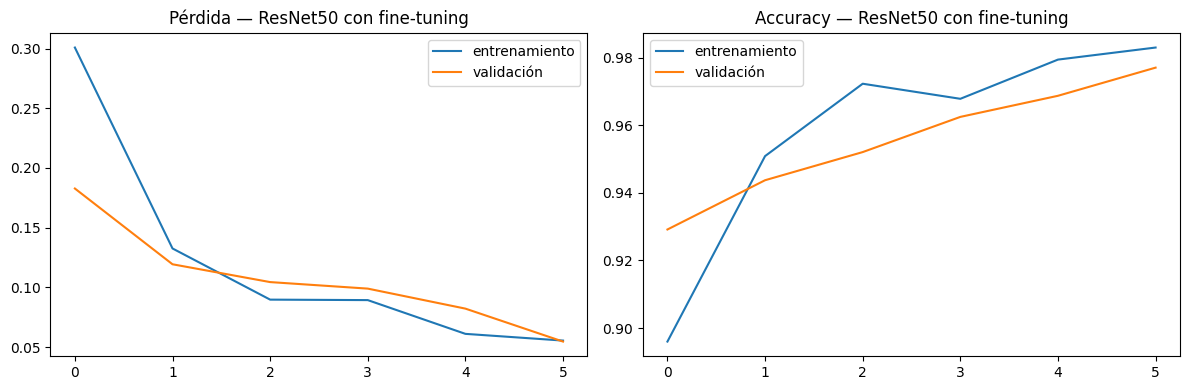

In [17]:
base_model.trainable = True
for capa in base_model.layers[:-30]:
    capa.trainable = False

modelo_visual.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_ft = modelo_visual.fit(
    train_ds,
    validation_data=val_ds,
    epochs=6,
    callbacks=callbacks
)
graficar_historia(history_ft, "ResNet50 con fine-tuning")

## 7. Evaluación del componente visual

Se calculan accuracy, precision, recall y F1-score, tanto de forma global como por clase, además de la matriz de confusión.

15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 132ms/step


,precision,recall,f1-score,support
saludable,0.922414,1.000000,0.959641,107.000000
tizon_temprano,0.964286,0.915254,0.939130,118.000000
tizon_tardio,0.978723,0.985714,0.982206,140.000000
mancha_bacteriana,1.000000,0.965217,0.982301,115.000000
accuracy,0.966667,0.966667,0.966667,0.966667
macro avg,0.966356,0.966546,0.965820,480.000000
weighted avg,0.967719,0.966667,0.966609,480.000000


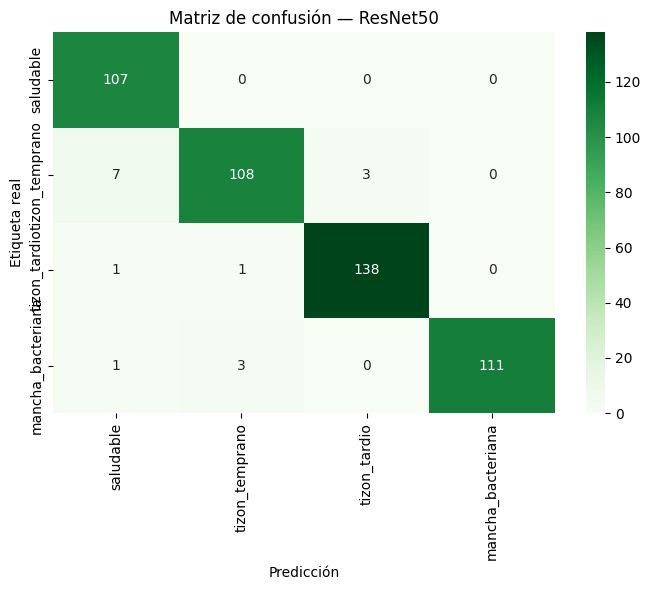

In [18]:
from sklearn.metrics import classification_report, confusion_matrix

y_real = np.concatenate([y.numpy() for _, y in test_ds])
probabilidades = modelo_visual.predict(test_ds, verbose=1)
y_pred = probabilidades.argmax(axis=1)

reporte_visual = classification_report(
    y_real, y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)
df_reporte_visual = pd.DataFrame(reporte_visual).T
display(df_reporte_visual)
df_reporte_visual.to_csv("metricas_modelo_visual.csv")

cm_visual = confusion_matrix(y_real, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm_visual, annot=True, fmt="d", cmap="Greens",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicción")
plt.ylabel("Etiqueta real")
plt.title("Matriz de confusión — ResNet50")
plt.tight_layout()
plt.savefig("matriz_confusion_visual.png", dpi=180, bbox_inches="tight")
plt.show()

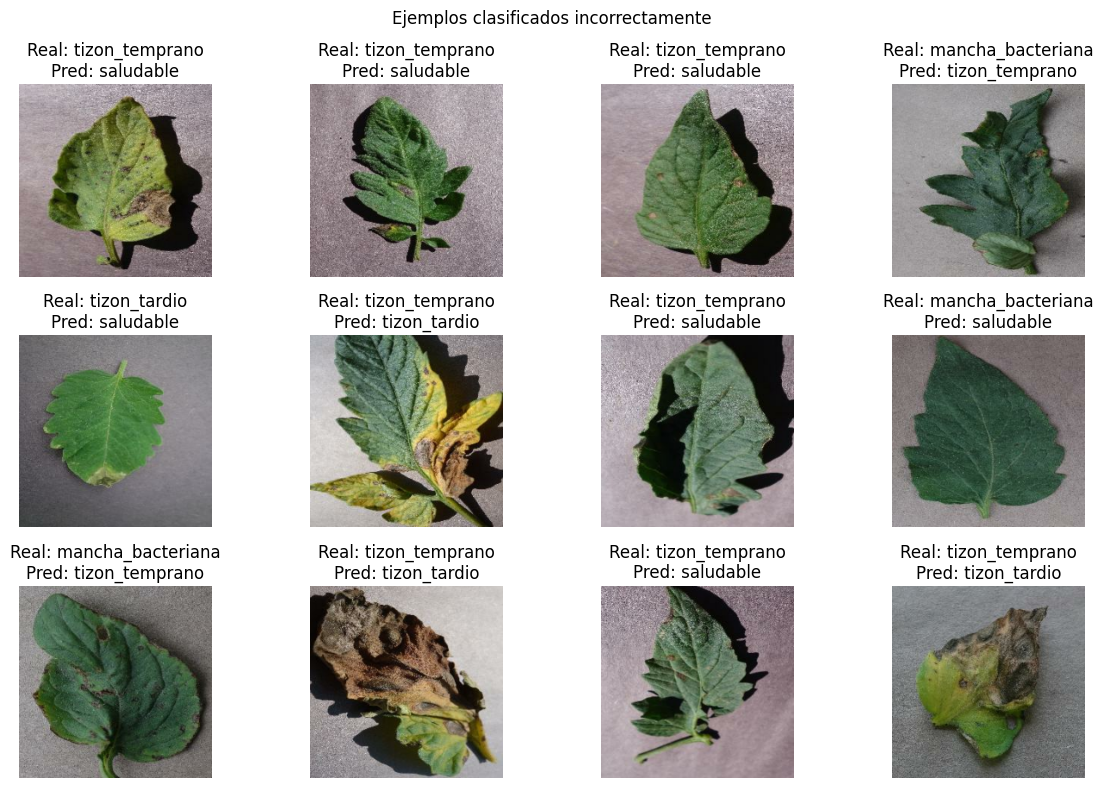

In [19]:
# Inspección cualitativa de errores.
imagenes_test = np.concatenate([x.numpy() for x, _ in test_ds])
indices_error = np.where(y_real != y_pred)[0]

plt.figure(figsize=(12, 8))
for posicion, indice in enumerate(indices_error[:12]):
    ax = plt.subplot(3, 4, posicion + 1)
    plt.imshow(tf.cast(imagenes_test[indice], tf.uint8))
    plt.title(f"Real: {class_names[y_real[indice]]}\nPred: {class_names[y_pred[indice]]}")
    plt.axis("off")
plt.suptitle("Ejemplos clasificados incorrectamente")
plt.tight_layout()
plt.show()

## 8. Integración multimodal

El sistema utiliza el modelo textual cuando recibe un mensaje y el modelo visual cuando recibe una imagen. Cuando llegan ambos elementos, la respuesta combina la intención conversacional con la condición visual estimada.

In [23]:
RESPUESTAS_INTENCION = {
    "saludo": "¡Hola! Soy HortiAmiga. Puedo orientarte sobre huertos urbanos y analizar hojas de jitomate.",
    "iniciar_huerto": "Para comenzar identifica el espacio, las horas de luz y recipientes con drenaje.",
    "recomendar_hortaliza": "Puedo recomendar cultivos según tu espacio, luz disponible y experiencia.",
    "consultar_temporada": "Indícame el cultivo y tu región para darte una temporada general de siembra.",
    "consultar_riego": "La frecuencia depende del cultivo, clima, recipiente y humedad del sustrato.",
    "consultar_iluminacion": "Dime el cultivo y cuántas horas de luz recibe el espacio.",
    "consultar_sustrato": "En maceta conviene un sustrato aireado, fértil y con buen drenaje.",
    "consultar_problema": "Puedo darte una orientación preventiva. Si tienes una hoja de jitomate, adjunta una fotografía.",
    "despedida": "¡Con gusto! Espero que tu huerto siga creciendo. Hasta pronto.",
    "fallback": "No reconocí la consulta. Puedes preguntarme sobre huertos, cultivos, cuidados o problemas visibles en hojas de jitomate."
}

ORIENTACION_VISUAL = {
    "saludable": "La hoja presenta características similares a una hoja saludable. Continúa observando riego, luz y aparición de cambios.",
    "tizon_temprano": "La imagen se parece a casos de tizón temprano. Retira hojas muy afectadas, evita mojar el follaje y vigila la propagación.",
    "tizon_tardio": "La imagen se parece a casos de tizón tardío. Aísla la planta si es posible y solicita orientación especializada si el daño avanza.",
    "mancha_bacteriana": "La imagen se parece a casos de mancha bacteriana. Evita manipular plantas húmedas y desinfecta herramientas después de usarlas."
}

def predecir_imagen(ruta_imagen):
    imagen = keras.utils.load_img(ruta_imagen, target_size=IMG_SIZE)
    arreglo = keras.utils.img_to_array(imagen)
    probs = modelo_visual.predict(np.expand_dims(arreglo, axis=0), verbose=0)[0]
    indice = int(np.argmax(probs))
    return {
        "clase": class_names[indice],
        "probabilidad": float(probs[indice]),
        "probabilidades": {class_names[i]: float(p) for i, p in enumerate(probs)}
    }

def procesar_consulta(texto=None, ruta_imagen=None):
    partes = []
    resultado = {}

    if texto and texto.strip():
        intencion = modelo_texto.predict([texto])[0]
        resultado["intencion"] = intencion
        partes.append(RESPUESTAS_INTENCION[intencion])

    if ruta_imagen:
        visual = predecir_imagen(ruta_imagen)
        resultado["visual"] = visual
        partes.append(
            f"Resultado visual: {visual['clase'].replace('_', ' ')} "
            f"({visual['probabilidad']:.1%}). {ORIENTACION_VISUAL[visual['clase']]}"
        )

    if not partes:
        partes.append("Escribe una consulta o proporciona una imagen.")

    partes.append("El análisis visual es orientativo y no constituye un diagnóstico profesional.")
    resultado["respuesta"] = " ".join(partes)
    return resultado

Saving images.jpg to images.jpg
Puedo darte una orientación preventiva. Si tienes una hoja de jitomate, adjunta una fotografía. Resultado visual: tizon temprano (73.6%). La imagen se parece a casos de tizón temprano. Retira hojas muy afectadas, evita mojar el follaje y vigila la propagación. El análisis visual es orientativo y no constituye un diagnóstico profesional.


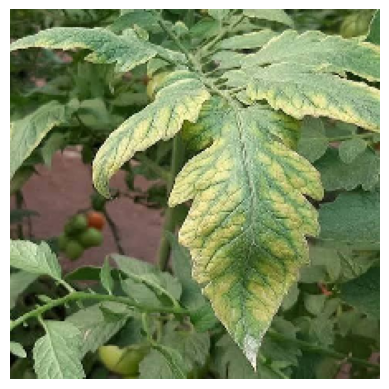

In [24]:
# Ejemplo en Colab: Imagen tomada de interneta combinarla con texto.
from google.colab import files

subida = files.upload()
ruta_imagen = next(iter(subida))
resultado_multimodal = procesar_consulta(
    texto="Mi jitomate tiene manchas en las hojas",
    ruta_imagen=ruta_imagen
)
print(resultado_multimodal["respuesta"])

imagen = keras.utils.load_img(ruta_imagen, target_size=IMG_SIZE)
plt.imshow(imagen)
plt.axis("off")
plt.show()

## 9. Resultados y limitaciones

Después de ejecutar el notebook, registra aquí los valores obtenidos:

- Mejor modelo textual: TF-IDF + SVM lineal
- Accuracy de prueba: 0.640
- Precision macro: 0.691
- Recall macro: 0.640
- F1 macro de prueba: 0.648
- F1 macro en validación cruzada: 0.686 ± 0.042


Limitaciones principales:

1. El conjunto textual es pequeño y fue construido para un dominio controlado.
2. La clase `fallback` no representa toda la diversidad de consultas fuera del dominio.
3. PlantVillage contiene imágenes con fondos relativamente controlados, por lo que el desempeño puede disminuir con fotografías reales de celulares.
4. El clasificador visual solo reconoce cuatro condiciones en hojas de jitomate.
5. Una predicción visual no equivale a un diagnóstico agronómico.
6. La integración combina resultados, pero todavía no conserva contexto entre varios turnos.

## 10. Conclusiones

Esta versión transforma HortiAmiga en un primer asistente multimodal. El componente textual aprende a clasificar intenciones a partir de ejemplos, mientras que el componente visual utiliza características aprendidas por ResNet50 para distinguir cuatro condiciones de hojas de jitomate. La comparación de modelos, las métricas por clase y el análisis de errores permiten documentar de manera verificable las fortalezas y limitaciones de la solución.

Las siguientes etapas pueden incorporar más fotografías tomadas en condiciones reales, calibración de confianza, memoria conversacional e integración web.

## 11. Referencias

- Documentación de NLTK: https://www.nltk.org/
- Documentación de scikit-learn: https://scikit-learn.org/stable/
- TensorFlow Datasets — PlantVillage: https://www.tensorflow.org/datasets/catalog/plant_village
- Keras Applications — ResNet: https://keras.io/api/applications/resnet/
- Hughes, D. P. y Salathé, M. (2015). *An open access repository of images on plant health to enable the development of mobile disease diagnostics*. arXiv:1511.08060.